<a href="https://colab.research.google.com/github/bonanigus/GS-ACV/blob/main/GS_ACV.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# CalçadaScan — Identificação experimental de possíveis buracos

**FIAP | Applied Computer Vision | Global Solution 2026.2**

**Equipe:** Gustavo Felex (RM 554242), Vinicius Issa Gois (RM 553814), Gustavo Bonani (RM 553493), Wesley Vieira (RM 553496).

Este notebook processa fotografias e **destaca regiões candidatas a buracos/danos** usando OpenCV e Segment Anything (SAM). **Não faz confirmação semântica de buracos**: vegetação, solo, sombras ou outros objetos podem gerar **falsos positivos**; danos podem não ser encontrados (**falsos negativos**). A área calculada corresponde à parcela da fotografia marcada como candidata, não à área real danificada ou à gravidade do risco.

**Para executar:** Google Colab → Ambiente de execução → Alterar tipo → GPU T4 → executar as células em sequência. Não utiliza SegFormer nem filtro obrigatório de calçada.

## 1 — Instalar dependências
Usamos o checkpoint público `sam_vit_b_01ec64.pth` do Segment Anything. A primeira execução baixa o modelo. A GPU é altamente recomendável.

In [ ]:
%pip -q install segment-anything opencv-python-headless matplotlib pillow pandas

## 2 — Configuração e carregamento do SAM
A configuração reproduz os testes de detecção de regiões candidatas, sem filtro de calçada. O arquivo do checkpoint é conferido antes de carregar, evitando reutilizar downloads incompletos.

In [ ]:
import cv2, torch, json, time, re, urllib.request, shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from io import BytesIO
from PIL import Image, ImageOps
from google.colab import files
from segment_anything import sam_model_registry, SamAutomaticMaskGenerator

CONFIG = {
    "max_lado": 1024,
    "points_per_side": 24,
    "pred_iou_thresh": 0.80,
    "stability_score_thresh": 0.85,
    "crop_n_layers": 0,
    "min_mask_region_area": 300,
    "proporcao_min": 0.03,
    "proporcao_max": 0.35,
    "top_n": 3,
    "distancia_px": 100,
    "expansao_max_relativa": 1.05,
}

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
OUTPUT_DIR = Path('/content/CalcadaScan_Resultados')
if OUTPUT_DIR.exists():
    shutil.rmtree(OUTPUT_DIR)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print('Dispositivo:', DEVICE)
if DEVICE != 'cuda':
    print('AVISO: CPU pode ser lenta. Recomenda-se ativar GPU T4 no Colab.')

CHECKPOINT = Path('/content/sam_vit_b_01ec64.pth')
URL_SAM = 'https://dl.fbaipublicfiles.com/segment_anything/sam_vit_b_01ec64.pth'
# Checkpoint ViT-B: aproximadamente 375 MB. O intervalo protege contra arquivos incompletos.
def checkpoint_parece_completo(path):
    return path.exists() and 350 * 1024**2 < path.stat().st_size < 400 * 1024**2

if not checkpoint_parece_completo(CHECKPOINT):
    CHECKPOINT.unlink(missing_ok=True)
    temporario = CHECKPOINT.with_suffix('.download')
    temporario.unlink(missing_ok=True)
    print('Baixando pesos SAM...', flush=True)
    try:
        urllib.request.urlretrieve(URL_SAM, str(temporario))
        if not checkpoint_parece_completo(temporario):
            raise RuntimeError('Download SAM incompleto (tamanho inesperado).')
        temporario.replace(CHECKPOINT)
    finally:
        temporario.unlink(missing_ok=True)

try:
    sam = sam_model_registry['vit_b'](checkpoint=str(CHECKPOINT))
except Exception as erro:
    CHECKPOINT.unlink(missing_ok=True)
    raise RuntimeError('Checkpoint SAM inválido. Execute novamente esta célula para baixar uma cópia nova.') from erro
sam.to(device=DEVICE)
sam.eval()
gerador = SamAutomaticMaskGenerator(
    model=sam,
    points_per_side=CONFIG['points_per_side'],
    pred_iou_thresh=CONFIG['pred_iou_thresh'],
    stability_score_thresh=CONFIG['stability_score_thresh'],
    crop_n_layers=CONFIG['crop_n_layers'],
    min_mask_region_area=CONFIG['min_mask_region_area']
)
print('Modelo SAM carregado.')

Dispositivo: cuda
Baixando pesos SAM...
Modelo SAM carregado.


## 3 — Funções de pré-processamento e visualização
As imagens intermediárias para a documentação são **grayscale**, suavização gaussiana, contraste CLAHE e bordas Canny. Elas são diagnósticas; a proposta de máscaras é produzida pelo SAM sobre a imagem RGB, enquanto a seleção heurística usa a textura Laplaciana da imagem em cinza.

In [ ]:
def normalizar_imagem(conteudo):
    img = ImageOps.exif_transpose(Image.open(BytesIO(conteudo))).convert('RGB')
    arr = np.asarray(img)
    h, w = arr.shape[:2]
    escala = min(1.0, CONFIG['max_lado'] / max(h, w))
    if escala < 1.0:
        arr = cv2.resize(arr, (max(1, round(w*escala)), max(1, round(h*escala))), interpolation=cv2.INTER_AREA)
    return np.ascontiguousarray(arr)


def gerar_transformacoes(rgb, pasta):
    cinza = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY)
    suave = cv2.GaussianBlur(cinza, (5,5), 0)
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8,8)).apply(suave)
    canny = cv2.Canny(clahe, 70, 150)
    nomes = ['original', 'grayscale', 'suavizacao', 'clahe', 'canny']
    imgs = [rgb, cinza, suave, clahe, canny]
    for nome, img in zip(nomes, imgs):
        if img.ndim == 3:
            cv2.imwrite(str(pasta / f'{nome}.png'), cv2.cvtColor(img,cv2.COLOR_RGB2BGR))
        else:
            cv2.imwrite(str(pasta / f'{nome}.png'), img)
    fig, axs = plt.subplots(1, 5, figsize=(19, 4))
    for ax, titulo, img in zip(axs, ['Original','Grayscale','Suavização','CLAHE','Canny'], imgs):
        ax.imshow(img, cmap='gray' if img.ndim == 2 else None)
        ax.set_title(titulo)
        ax.axis('off')
    fig.tight_layout()
    fig.savefig(pasta/'transformacoes.png', dpi=140, bbox_inches='tight')
    plt.show()
    plt.close(fig)
    return cinza


def sobrepor(rgb, mascara, alpha=0.45):
    out = rgb.copy().astype(np.float32)
    out[mascara] = out[mascara]*(1-alpha) + np.array([255,0,0])*alpha
    return out.astype(np.uint8)

## 4 — Classificar regiões candidatas por heurísticas
O SAM não reconhece a classe “buraco”; gera máscaras de objetos e superfícies. O ranking experimental usa área relativa, textura (Laplaciano) e alongamento. Áreas vegetadas podem receber pontuação alta: **falso positivo é possível**.

In [ ]:
def selecionar_candidatos(mascaras, rgb):
    h, w = rgb.shape[:2]
    cinza = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY)
    textura = np.abs(cv2.Laplacian(cinza, cv2.CV_32F, ksize=3))
    avaliados = []
    for indice, item in enumerate(mascaras):
        m = item['segmentation'].astype(bool)
        proporcao = float(m.mean())
        if not CONFIG['proporcao_min'] <= proporcao <= CONFIG['proporcao_max']:
            continue
        ys, xs = np.where(m)
        if len(xs) == 0:
            continue
        dx, dy = xs.max()-xs.min()+1, ys.max()-ys.min()+1
        alongamento = max(dx/dy, dy/dx)
        rugosidade = float(textura[m].mean())
        score = rugosidade*0.5 + min(alongamento,5)*10 + proporcao*100*0.5
        avaliados.append({
            'indice_mascara': indice,
            'mascara': m,
            'area_pixels': int(m.sum()),
            'percentual_imagem': round(proporcao*100, 4),
            'indice_textura': round(rugosidade, 4),
            'alongamento': round(float(alongamento),4),
            'score': round(float(score),4),
        })
    avaliados.sort(key=lambda d: d['score'], reverse=True)
    for pos, item in enumerate(avaliados, 1):
        item['numero_candidato'] = pos
    return avaliados


def exibir_candidatos(rgb, avaliados, pasta, total=3):
    fig, axs = plt.subplots(1, total+1, figsize=(5*(total+1), 6))
    axs[0].imshow(rgb); axs[0].set_title('Original'); axs[0].axis('off')
    for i in range(total):
        ax = axs[i+1]
        if i < len(avaliados):
            item = avaliados[i]
            ax.imshow(sobrepor(rgb,item['mascara']))
            ax.set_title(f"Candidato {item['numero_candidato']} | Área: {item['percentual_imagem']:.2f}%\nPontuação: {item['score']:.1f}")
        else:
            ax.imshow(rgb); ax.set_title('Sem candidato')
        ax.axis('off')
    fig.tight_layout()
    fig.savefig(pasta/'candidatos.png',dpi=150,bbox_inches='tight')
    plt.show();plt.close(fig)

## 5 — Combinar candidatos próximos
Consideramos até três candidatos com maior pontuação e combinamos quando a distância e a expansão relativa estiverem nos limites. Os números exibidos são **candidato 1, candidato 2...**, não os índices internos do SAM. Essas regras não garantem identificação correta.

In [ ]:
def combinar_regioes(avaliados, rgb, pasta):
    top = avaliados[:CONFIG['top_n']]
    if not top:
        return np.zeros(rgb.shape[:2], dtype=bool), [], [], []

    combinado = top[0]['mascara'].copy()
    area_principal = int(combinado.sum())
    numeros = [top[0]['numero_candidato']]
    indices = [top[0]['indice_mascara']]
    rejeitados = []

    for item in top[1:]:
        candidato_n = item['numero_candidato']
        m = item['mascara']
        area_nova = int((m & ~combinado).sum())
        if area_nova > area_principal * CONFIG['expansao_max_relativa']:
            rejeitados.append({'candidato':candidato_n,'motivo':'expansão excessiva','area_nova_pixels':area_nova})
            continue
        mapa_distancia = cv2.distanceTransform((~combinado).astype(np.uint8),cv2.DIST_L2,5)
        distancia_min = float(mapa_distancia[m].min())
        if distancia_min > CONFIG['distancia_px']:
            rejeitados.append({'candidato':candidato_n,'motivo':'distância excessiva','distancia_pixels':round(distancia_min,2)})
            continue
        combinado |= m
        numeros.append(candidato_n)
        indices.append(item['indice_mascara'])

    print('Candidatos combinados:', numeros)
    print('Índices internos SAM:', indices)
    if rejeitados: print('Candidatos não combinados:', rejeitados)
    fig, ax = plt.subplots(figsize=(8,10))
    ax.imshow(sobrepor(rgb, combinado))
    ax.set_title('CalçadaScan — Candidatos combinados: '+str(numeros))
    ax.axis('off')
    fig.tight_layout()
    fig.savefig(pasta/'mascara_combinada.png',dpi=160,bbox_inches='tight')
    plt.show();plt.close(fig)
    cv2.imwrite(str(pasta/'mascara_binaria.png'), combinado.astype(np.uint8)*255)
    return combinado, numeros, indices, rejeitados

## 6 — Resultado e relatório de candidatos
Os resultados registram **regiões potencialmente danificadas**, e não “dano confirmado”, “calçada segura” ou severidade clínica/técnica. Uma foto sem candidatos **não prova ausência de buracos**. Sempre interpretar as máscaras visualmente.

In [ ]:
def salvar_resultado(rgb, mascara, pasta, nome, qtd_mascaras, avaliados, combinados, indices, rejeitados, tempo):
    h, w = rgb.shape[:2]
    area_px = int(mascara.sum())
    percentual = 100*area_px/(h*w)
    binaria = (mascara.astype(np.uint8)*255)
    contornos, _ = cv2.findContours(binaria, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    anotada = rgb.copy()
    caixa = None
    if contornos:
        cv2.drawContours(anotada,contornos,-1,(255,0,0),2)
        ys,xs=np.where(mascara)
        x0,y0,x1,y1=int(xs.min()),int(ys.min()),int(xs.max()),int(ys.max())
        caixa={'x':x0,'y':y0,'largura':x1-x0+1,'altura':y1-y0+1}
        cv2.rectangle(anotada,(x0,y0),(x1,y1),(0,255,0),2)
    bw=min(w-1, 485); bh=min(h-1, 85)
    if bw > 20 and bh > 30:
        cv2.rectangle(anotada,(5,5),(bw,bh),(0,0,0),-1)
        fonte=min(0.70,max(0.40,w/1250))
        cv2.putText(anotada,f'Area candidata: {percentual:.2f}% da imagem',(12,min(h-1,36)),cv2.FONT_HERSHEY_SIMPLEX,fonte,(255,255,255),2,cv2.LINE_AA)
        cv2.putText(anotada,'Possiveis falsos positivos',(12,min(h-1,70)),cv2.FONT_HERSHEY_SIMPLEX,fonte,(255,255,255),2,cv2.LINE_AA)
    cv2.imwrite(str(pasta/'resultado_anotado.png'),cv2.cvtColor(anotada,cv2.COLOR_RGB2BGR))
    fig, ax=plt.subplots(figsize=(8,10))
    ax.imshow(anotada);ax.set_title('CalçadaScan — resultado experimental');ax.axis('off')
    fig.tight_layout();plt.show();plt.close(fig)

    relatorio = {
        'projeto':'CalçadaScan', 'nome_imagem':nome,
        'metodo':'SAM automático + classificação heurística + combinação por distância e expansão',
        'dimensoes_processadas':{'largura':w,'altura':h},
        'tempo_segmentacao_segundos':round(tempo,2),
        'total_mascaras_SAM':qtd_mascaras,
        'total_candidatos_apos_filtro':len(avaliados),
        'candidatos_combinados':combinados,
        'indices_internos_mascaras_combinadas':indices,
        'candidatos_rejeitados_na_uniao':rejeitados,
        'area_segmentada_pixels':area_px,
        'percentual_da_imagem':round(percentual,2),
        'status_analise':'sem_candidatos_nos_filtros' if not avaliados else 'regioes_candidatas_nao_confirmadas',
        'caixa_delimitadora_pixels':caixa,
        'parametros':CONFIG.copy(),
        'limitacoes':[
            'SAM segmenta regiões, não detecta semanticamente danos.',
            'Pontuação, seleção e união são heurísticas não validadas.',
            'Percentual corresponde à imagem, não à área real da calçada.',
            'Não é atribuída classe de severidade ou confirmação de dano.',
            'É possível haver falsos positivos (ex.: grama lateral) e falsos negativos.'
        ]
    }
    with open(pasta/'relatorio.json','w',encoding='utf-8') as f:
        json.dump(relatorio,f,indent=2,ensure_ascii=False)
    df=pd.DataFrame([{k:v for k,v in item.items() if k != 'mascara'} for item in avaliados])
    df.to_csv(pasta/'candidatos.csv',index=False,encoding='utf-8-sig')
    print(json.dumps({k:v for k,v in relatorio.items() if k not in ['limitacoes','parametros']},ensure_ascii=False,indent=2))
    return relatorio

## 7 — Upload e execução do processamento
Envie uma ou mais fotos. Cada uma recebe uma pasta contendo transformações, máscaras, candidatos e resultados. **Regiões destacadas são suspeitas, não diagnóstico de buraco**.

Saving WhatsApp Image 2026-11-17 at 22.09.53.jpeg to WhatsApp Image 2026-11-17 at 22.09.53.jpeg

===== Foto 1/1: WhatsApp Image 2026-11-17 at 22.09.53.jpeg =====


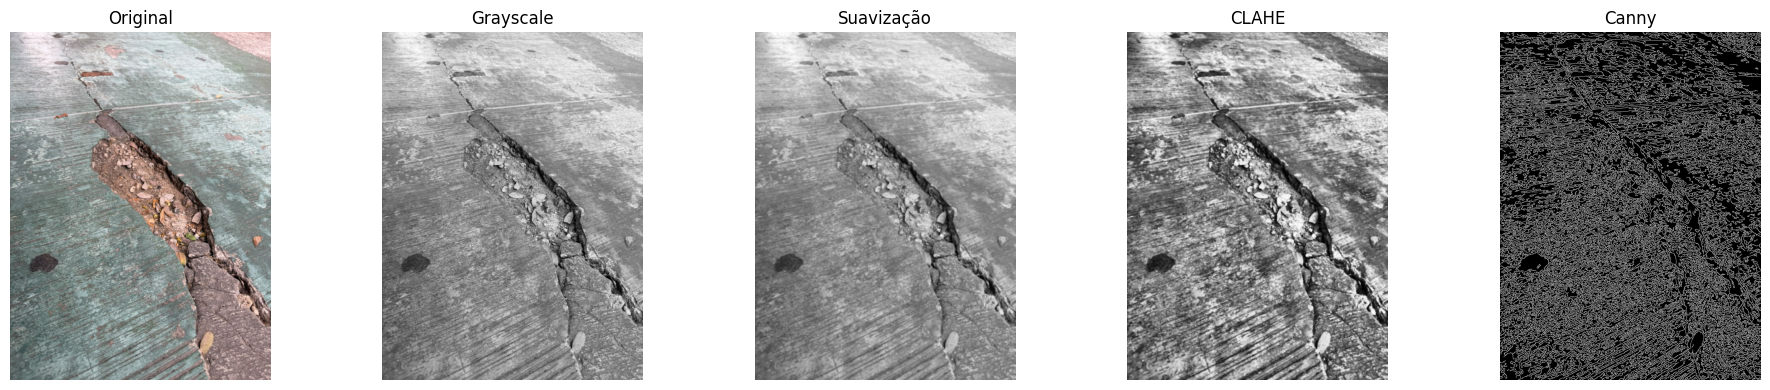

Máscaras SAM: 67 | Tempo: 4.78s
Regiões candidatas após filtro: 3


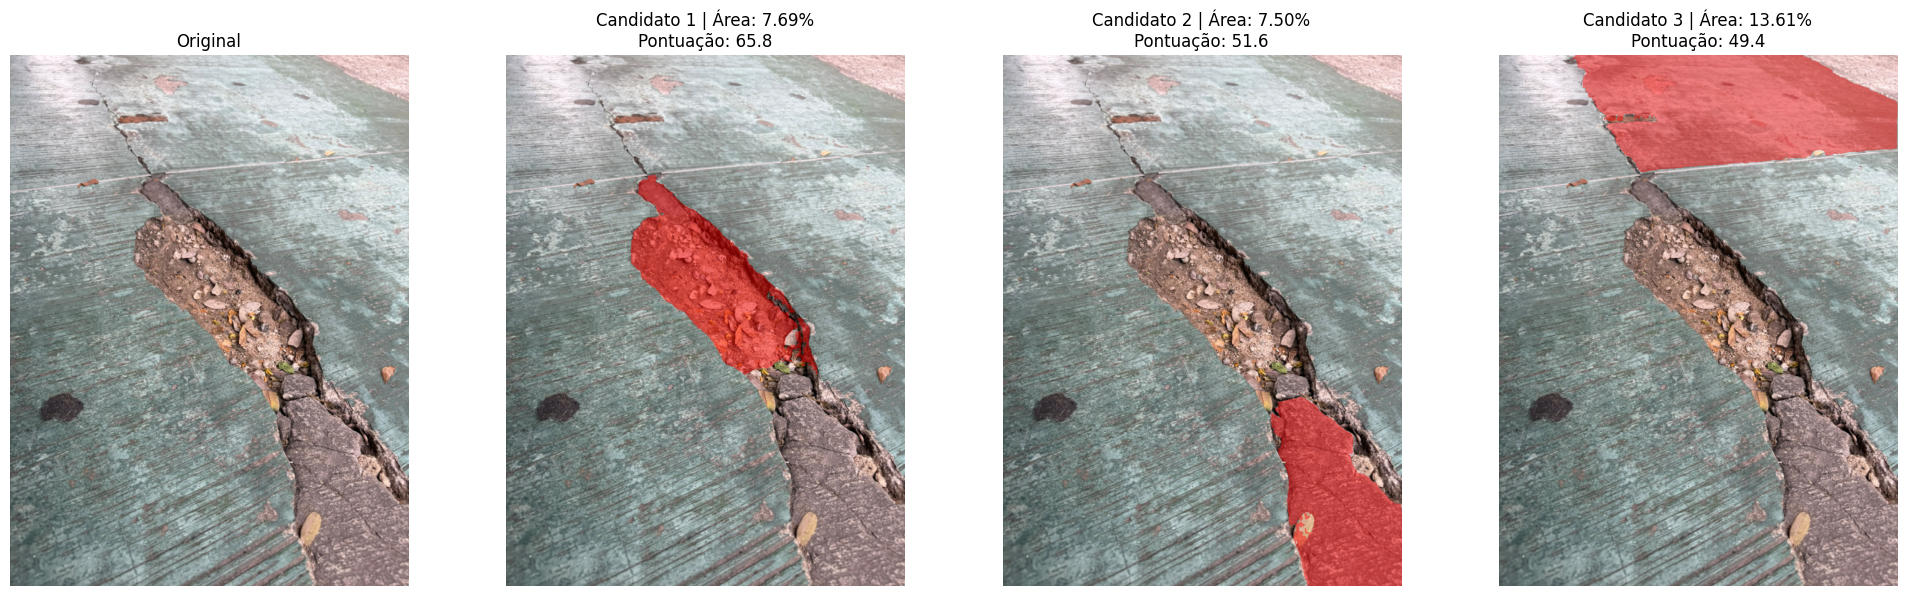

Candidatos combinados: [1, 2]
Índices internos SAM: [46, 35]
Candidatos não combinados: [{'candidato': 3, 'motivo': 'expansão excessiva', 'area_nova_pixels': 107004}]


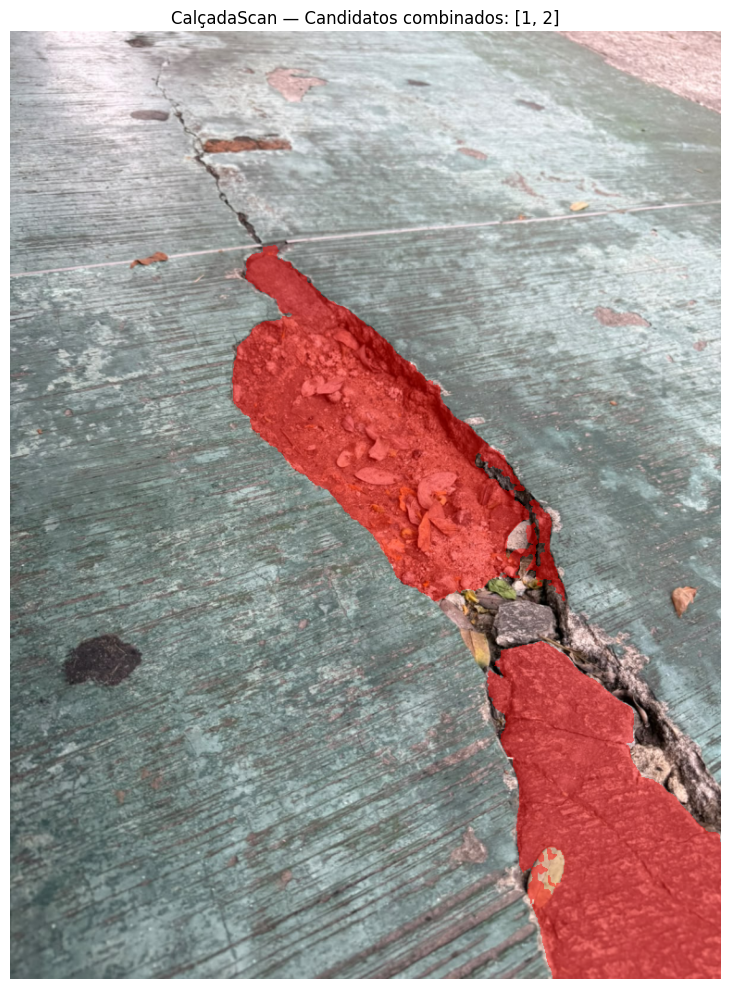

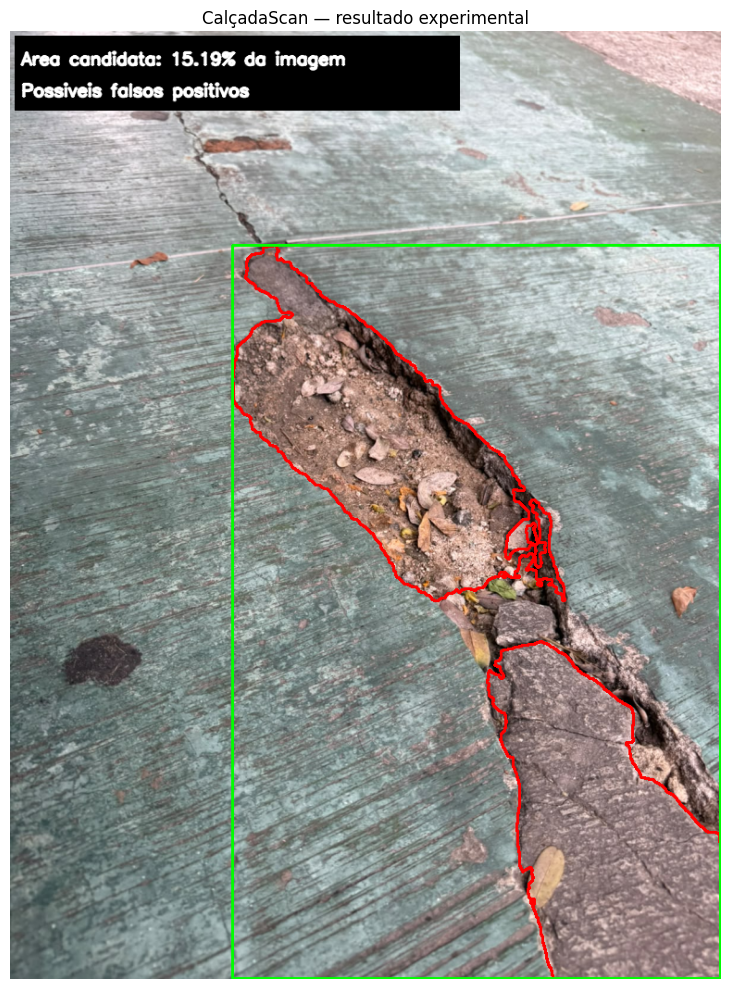

{
  "projeto": "CalçadaScan",
  "nome_imagem": "WhatsApp Image 2026-11-17 at 22.09.53.jpeg",
  "metodo": "SAM automático + classificação heurística + combinação por distância e expansão",
  "dimensoes_processadas": {
    "largura": 768,
    "altura": 1024
  },
  "tempo_segmentacao_segundos": 4.78,
  "total_mascaras_SAM": 67,
  "total_candidatos_apos_filtro": 3,
  "candidatos_combinados": [
    1,
    2
  ],
  "indices_internos_mascaras_combinadas": [
    46,
    35
  ],
  "candidatos_rejeitados_na_uniao": [
    {
      "candidato": 3,
      "motivo": "expansão excessiva",
      "area_nova_pixels": 107004
    }
  ],
  "area_segmentada_pixels": 119478,
  "percentual_da_imagem": 15.19,
  "status_analise": "regioes_candidatas_nao_confirmadas",
  "caixa_delimitadora_pixels": {
    "x": 240,
    "y": 231,
    "largura": 528,
    "altura": 793
  }
}

Resumo geral:


,imagem,status,mascaras_SAM,candidatos,combinados,percentual_imagem,tempo_sam_s
0,WhatsApp Image 2026-11-17 at 22.09.53.jpeg,analisada,67,3,"[1, 2]",15.19,4.78


In [ ]:
arquivos = files.upload()
if not arquivos:
    raise ValueError('Nenhuma fotografia enviada.')

resumos = []
for numero, (nome, conteudo) in enumerate(arquivos.items(), start=1):
    pasta_nome = re.sub(r'[^A-Za-z0-9_-]+','_', Path(nome).stem)[:55] or 'imagem'
    pasta = OUTPUT_DIR / f'{numero:02d}_{pasta_nome}'
    pasta.mkdir(parents=True, exist_ok=True)
    print(f'\n===== Foto {numero}/{len(arquivos)}: {nome} =====', flush=True)
    try:
        imagem_rgb = normalizar_imagem(conteudo)
        gerar_transformacoes(imagem_rgb, pasta)
        inicio = time.perf_counter()
        mascaras = gerador.generate(imagem_rgb)
        tempo = time.perf_counter()-inicio
        print(f'Máscaras SAM: {len(mascaras)} | Tempo: {tempo:.2f}s', flush=True)
        avaliados = selecionar_candidatos(mascaras,imagem_rgb)
        print('Regiões candidatas após filtro:',len(avaliados))
        exibir_candidatos(imagem_rgb, avaliados, pasta, total=3)
        mascara_final, combinados, indices, rejeitados = combinar_regioes(avaliados, imagem_rgb, pasta)
        relatorio = salvar_resultado(imagem_rgb,mascara_final,pasta,nome,len(mascaras),avaliados,combinados,indices,rejeitados,tempo)
        resumos.append({'imagem':nome,'status':'analisada','mascaras_SAM':len(mascaras),'candidatos':len(avaliados),'combinados':str(combinados),'percentual_imagem':relatorio['percentual_da_imagem'],'tempo_sam_s':round(tempo,2)})
    except Exception as e:
        print('Falha nesta foto:',repr(e))
        resumos.append({'imagem':nome,'status':'erro','detalhe':str(e)})

pd.DataFrame(resumos).to_csv(OUTPUT_DIR/'resumo_geral.csv',index=False,encoding='utf-8-sig')
print('\nResumo geral:')
display(pd.DataFrame(resumos))

## 8 — Download dos resultados
O ZIP inclui, por foto: original e transformações intermediárias, candidatos, máscara combinada/binária, imagem anotada, `candidatos.csv` e `relatorio.json`; inclui ainda o `resumo_geral.csv`. Faça upload das evidências em um repositório/pasta pública e coloque os links no PDF de entrega.

In [ ]:
ARQUIVO_ZIP = '/content/CalcadaScan_Resultados.zip'
shutil.make_archive('/content/CalcadaScan_Resultados','zip',root_dir=OUTPUT_DIR)
print('ZIP gerado:', ARQUIVO_ZIP)
files.download(ARQUIVO_ZIP)

ZIP gerado: /content/CalcadaScan_Resultados.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>